# Hyperelasticity

A compressible neo-Hookean beam under large deformation, following the hyperelasticity
chapter of the [FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/) and the
hyperelasticity demo among the [DOLFINx demos](https://docs.fenicsproject.org/dolfinx/main/python/demos.html).
With the deformation gradient $F = I + \nabla u$, $C = F^T F$ and $J = \det F$, the strain energy density is

$$ \psi(u) = \frac{\mu}{2}\,(\mathrm{tr}\,C - 3) - \mu \ln J + \frac{\lambda}{2}(\ln J)^2 , $$

and the total potential energy, with a body force $B$ and a surface traction $T$, is

$$ \Pi(u) = \int_\Omega \psi(u)\, dx - \int_\Omega B\cdot u\, dx - \int_{\Gamma_T} T\cdot u\, ds . $$

The equilibrium state is a stationary point: $F(u; v) = \delta\Pi(u)[v] = 0$ for all test
functions $v$.  UFL's `derivative` produces this residual, and a second `derivative`
its Jacobian, so no tangent has to be derived by hand.

## Mesh, space and material

The beam $(0,1)\times(0,0.2)\times(0,0.2)$ is clamped at the face with number 1 ($x=0$); as in Firedrake the faces of a `BoxMesh` are numbered 1 ($x=0$), 2 ($x=1$), 3 ($y=0$), 4 ($y=0.2$), 5 ($z=0$), 6 ($z=0.2$).  The unknown is a
vector valued second order function; since the problem is nonlinear it is a `Function`, not a `TrialFunction`.

In [1]:
from ngsufl import *

mesh = BoxMesh(8, 2, 2, 1.0, 0.2, 0.2)
V = VectorFunctionSpace(mesh, "CG", 2)
u = Function(V, name="u")
v = TestFunction(V)
du = TrialFunction(V)
print(V.dim(), "dofs")

E, nu = 1.0e3, 0.3
mu = Constant(E / (2 * (1 + nu)))
lmbda = Constant(E * nu / ((1 + nu) * (1 - 2 * nu)))

1275 dofs


## Energy, residual and Jacobian

The loads are multiplied by a `Constant` that is ramped from 0 to 1 below.  Writing the
energy as a function of the displacement lets us reuse it for a second unknown later on.

UFL estimates the quadrature degree from the integrand.  With $\det F$ and $\ln J$ in the
energy the estimate reaches 11 for the residual and 17 for the Jacobian on quadratic
elements, far more than a smooth hyperelastic solution needs, so we ask for degree 4 in
the volume integral with `dx(degree=4)`.

In [2]:
step = Constant(0.0)
B = Constant((0.0, 0.0, -10.0))
T = Constant((0.0, 0.0, -5.0))


def potential_energy(u):
    F = Identity(len(u)) + grad(u)
    J = det(F)
    psi = (mu / 2) * (tr(F.T * F) - 3) - mu * ln(J) + (lmbda / 2) * ln(J)**2
    return psi * dx(degree=4) - step * dot(B, u) * dx - step * dot(T, u) * ds(2)


Pi = potential_energy(u)
residual = derivative(Pi, u, v)
jacobian = derivative(residual, u, du)

## Load stepping

Newton's method for the full load may not converge from $u=0$, so the load factor is raised
in steps.  Each solve starts from the previous solution.  `NonlinearVariationalSolver`
reports the number of Newton iterations.

In [3]:
bc = DirichletBC(V, Constant((0.0, 0.0, 0.0)), 1)
problem = NonlinearVariationalProblem(residual, u, bcs=bc, J=jacobian)
parameters = {"snes_rtol": 1e-10, "snes_atol": 1e-10}
solver = NonlinearVariationalSolver(problem, solver_parameters=parameters)

nsteps = 5
for k in range(1, nsteps + 1):
    step.assign(k / nsteps)
    solver.solve()
    print(f"load factor {k / nsteps:.1f}: {solver.iterations} Newton iterations, "
          f"tip {u.at(1.0, 0.1, 0.1)}")

load factor 0.2: 5 Newton iterations, tip (-0.01672884076996665, 0.00014217216222323211, -0.1719570201451356)


load factor 0.4: 6 Newton iterations, tip (-0.0600376690507222, 0.0002518310093868649, -0.32221842686335295)


load factor 0.6: 6 Newton iterations, tip (-0.1163571481468585, 0.00033044165711740623, -0.4421566239314427)


load factor 0.8: 6 Newton iterations, tip (-0.17507773062690815, 0.00038654014068692, -0.534215178689563)


load factor 1.0: 5 Newton iterations, tip (-0.23073456433570974, 0.00042839652858256617, -0.6045169812591233)


## Solving without a Jacobian

If `J` is left out, NGSolve differentiates the residual itself.  We solve the full load in a
single step with this variant, starting from zero, and compare with the stepped solution.
The problem is only moderately nonlinear, so Newton copes with the full load at once.

In [4]:
u2 = Function(V, name="u2")
res2 = derivative(potential_energy(u2), u2, v)
solver2 = NonlinearVariationalSolver(NonlinearVariationalProblem(res2, u2, bcs=bc),
                                     solver_parameters=parameters)
solver2.solve()
print("Newton iterations without J:", solver2.iterations)
print("tip, UFL Jacobian :", u.at(1.0, 0.1, 0.1))
print("tip, NGSolve diff.:", u2.at(1.0, 0.1, 0.1))
print("difference of the two solutions (L2):", errornorm(u, u2))

Newton iterations without J: 9
tip, UFL Jacobian : (-0.23073456433570974, 0.00042839652858256617, -0.6045169812591233)
tip, NGSolve diff.: (-0.23073456433652673, 0.00042839652886082763, -0.604516981259504)
difference of the two solutions (L2): 8.940583826710344e-14


## Deformed beam

`plot` is an ngsufl convenience for 3D results (Firedrake would write a VTK file).
The deflection is a sizeable fraction of the beam length, and the tip has moved towards the
clamp in $x$ (see the first tip component above), which a linear model cannot capture.

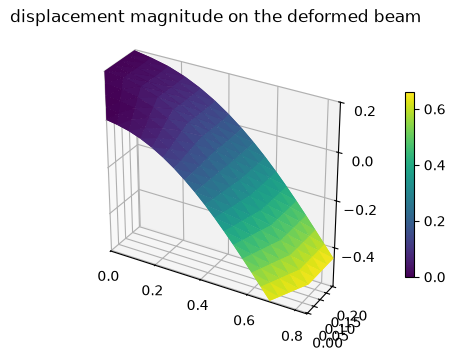

In [5]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(9, 4))
ax = fig.add_subplot(projection="3d")
plot(sqrt(dot(u, u)), ax=ax, deformation=u, subdivision=2)
ax.set_aspect("equal")
ax.set_title("displacement magnitude on the deformed beam");